**Step 1: Import Libraries**

In [2]:
# data handling
import pandas as pd
import numpy as np

# spliting
from sklearn.model_selection import train_test_split

# preprocessing 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# deep learning core
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model # Required instead of Sequential for multi-output networks # type: ignore
from tensorflow.keras.layers import Input, Dense, BatchNormalization, ReLU, Dropout # type: ignore
from tensorflow.keras.callbacks import EarlyStopping # type: ignore

# metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

**Step 2: Load dataset**

In [3]:
df = pd.read_csv(r"D:\Deep Learning\Projects\ANN\2_House_ANN_Project\Data\house_clean.csv")
df.head()

,area,bedrooms,bathrooms,floors,age,distance,garage,parking,garden,security,...,public_transport,crime_rate,population_density,location,income_level,price,Area_per_Bedroom,Bathroom_per_Bedroom,LuxuryScore,Accessibility
0,1360,6,2,2,9,10,0,0,1,0,...,0,6.939333,7242,premium,low,5.952493e+05,226.666667,0.333333,1,2
1,4272,5,2,3,24,8,1,0,0,1,...,0,0.400918,7729,low,low,1.571208e+06,854.400000,0.400000,2,3
2,3592,1,4,3,4,20,0,1,1,1,...,1,6.292386,1081,premium,mid,1.379943e+06,3592.000000,4.000000,3,2
3,966,5,2,2,6,14,1,0,0,0,...,0,8.964112,8912,medium,low,4.367819e+05,193.200000,0.400000,1,2
4,4926,4,3,1,18,9,0,0,0,0,...,1,2.843309,8146,low,mid,1.792425e+06,1231.500000,0.750000,0,3


**Step 3: Features & Targets**

In [4]:
X = df.drop(columns=['income_level','price'])
y = df['income_level']

**Step 4: Train-test-split**

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

**Step 5: Preprocessing pipeline**

In [6]:
df['income_level'].value_counts()

income_level
mid     16738
low     16651
high    16611
Name: count, dtype: int64

**Encode Target**

In [7]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

**Encode Features**

In [8]:
# All other features are numeric (including the already encoded income_level)
num_cols = [
    'area', 'bedrooms', 'bathrooms', 'floors', 'age', 'distance', 
    'garage', 'parking', 'garden', 'security', 'school_nearby', 
    'hospital_nearby', 'shopping_mall_nearby', 'public_transport', 
    'crime_rate', 'population_density', 'Area_per_Bedroom', 
    'Bathroom_per_Bedroom', 'LuxuryScore', 'Accessibility'
]

# The text column that needs encoding
cat_cols = ['location']

#create pipelines
num_transformer = Pipeline([
    ('imp',SimpleImputer(strategy='median')),
    ('scr',StandardScaler())
])
cat_transformer  = Pipeline([
    ('imp',SimpleImputer(strategy='most_frequent')),

    # 'sparse_output=False' --> ensures it returns a normal numpy array instead of a matrix
    # 'drop='first'' --> removes one column per feature to prevent the dummy variable trap
    ('scr',OneHotEncoder(drop='first',sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num_preprocessing',num_transformer,num_cols),
    ('cat_preprocessing',cat_transformer,cat_cols)
],remainder='passthrough')

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 6: Build ANN**

In [9]:
model = Sequential([
    # input layer
    Input(shape=(X_train_processed.shape[1],)), # Add a comma after the integer to convert it into a one-dimensional tuple

    # hidden layer 1
    Dense(128),                         # Removed activation to place before BatchNorm
    BatchNormalization(),               # Batch normalization for more stable training
    ReLU(),                             
    Dropout(0.3),                        # Dropout to reduce overfitting.

    # hidden layer 2
    Dense(64),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    #hidden layer 3
    Dense(32),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    #hidden layer 4
    Dense(16),
    BatchNormalization(),
    ReLU(),
    Dropout(0.3),

    # output layer
    Dense(3, activation="softmax")  # Must be 3 units for low, mid, high
])

**Step 7: Compile model**

In [10]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",     # binary_crossentropy(0,1)
    metrics=["accuracy"]
)

**Step 8: model summary**

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,819 (57.89 KB)

 Trainable params: 14,339 (56.01 KB)

 Non-trainable params: 480 (1.88 KB)

**Step 9: Train Model**

In [12]:
# batch_size = The model processes 100 rows of data at a time.
# epochs = The model will see the whole dataset 10 times in total
# validation_data = to get testing accuracy
# callbacks = stops overfitting when occur

history = model.fit(
    X_train_processed, y_train_encoded,
    validation_split=0.2,
    batch_size=100,
    epochs=50,
    callbacks=EarlyStopping()
)

Epoch 1/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.3322 - loss: 1.2414 - val_accuracy: 0.3368 - val_loss: 1.1032
Epoch 2/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3363 - loss: 1.1238 - val_accuracy: 0.3354 - val_loss: 1.0999
Epoch 3/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3363 - loss: 1.1093 - val_accuracy: 0.3388 - val_loss: 1.0992
Epoch 4/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3339 - loss: 1.1021 - val_accuracy: 0.3370 - val_loss: 1.0987
Epoch 5/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3309 - loss: 1.1015 - val_accuracy: 0.3399 - val_loss: 1.0986
Epoch 6/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3354 - loss: 1.0997 - val_accuracy: 0.3392 - val_loss: 1.0985
Epoch 7/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3371 - loss: 1.0992 - val_accuracy: 0.3410 - val_loss: 1.0986


**Step 10: Predict Model**

In [13]:
# 1. Get the 3 probability columns from your Keras model
y_pred_probs = model.predict(X_test_processed)

# 2. Extract the index of the highest probability column per row
y_pred_classes = np.argmax(y_pred_probs, axis=-1) 


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


**Step 11: Evaluate Model**

In [14]:
# Evaluate the model on the test data to get final test loss and accuracy
loss, accuracy = model.evaluate(X_test_processed, y_test_encoded, verbose=0)

print(f"Test Loss:     {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss:     1.0992
Test Accuracy: 0.3299


**Step 12: Classification report**

In [15]:
# (0 = low, 1 = mid, 2 = high)
target_names = ['low', 'mid', 'high']
report = classification_report(y_test_encoded,y_pred_classes,target_names=target_names,zero_division=True)
print(report)

              precision    recall  f1-score   support

         low       0.33      0.77      0.46      3212
         mid       0.35      0.05      0.09      3359
        high       0.34      0.19      0.24      3429

    accuracy                           0.33     10000
   macro avg       0.34      0.34      0.26     10000
weighted avg       0.34      0.33      0.26     10000



**Step 13: Confusion matrix**

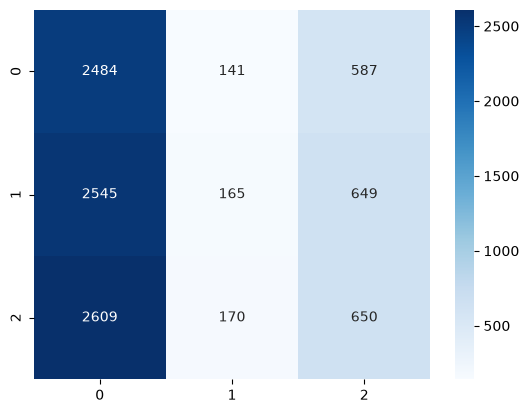

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_encoded, y_pred_classes)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.show()

**Step 14: Training Curve**

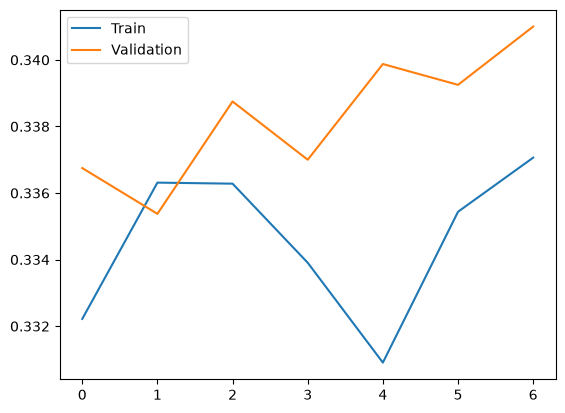

In [17]:
# here only accuracy / loss curve

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.show()

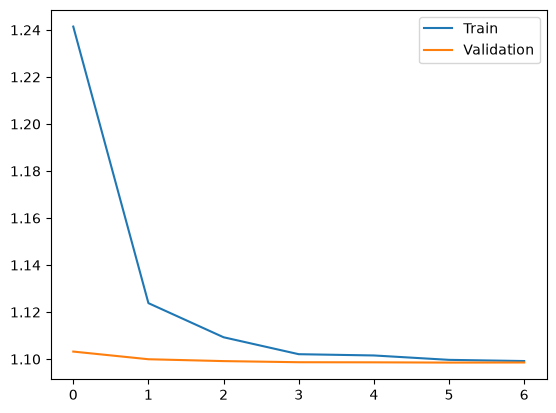

In [18]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.show()

**Step 15: Save Model**

In [19]:
model.save("../Models/incomelevel_model.keras")
print("Model Saved successfully...!")

Model Saved successfully...!
